In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

import numpy as np
import matplotlib.pyplot as plt



In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

In [ ]:
print(f"X_train Shape : {X_train.shape}")
print(f"y_train Shape : {y_train.shape}")

print(f"X_test Shape : {X_test.shape}")
print(f"y_test Shape : {y_test.shape}")

X_train Shape : (60000, 28, 28)
y_train Shape : (60000,)
X_test Shape : (10000, 28, 28)
y_test Shape : (10000,)


0


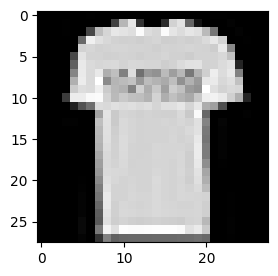

In [ ]:
plt.figure(figsize=(3, 3))
plt.imshow(X_train[16769], cmap='gray')
print(y_train[16769])

In [ ]:
label_dict = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

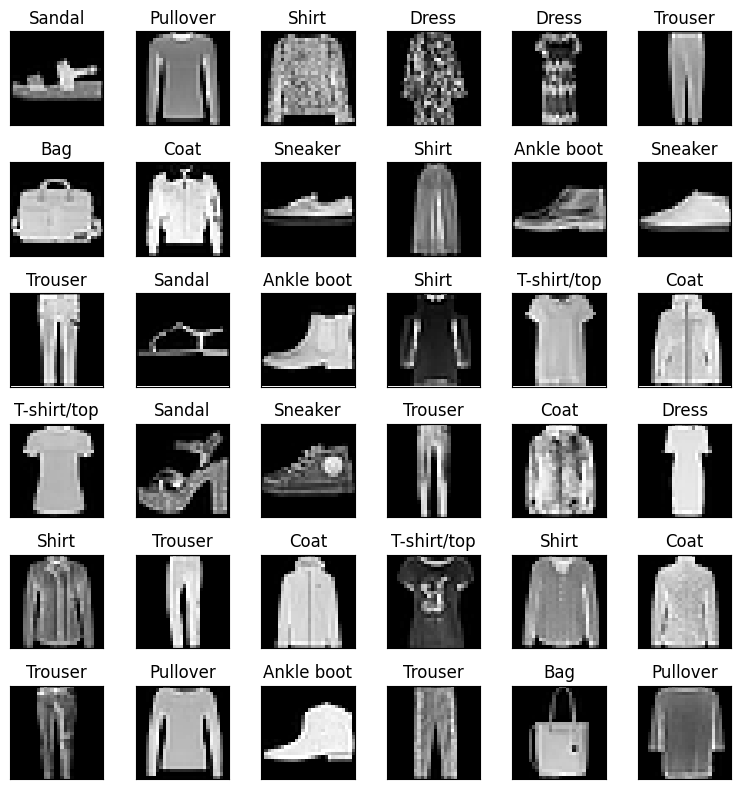

In [ ]:
plt.figure(figsize=(8, 8))
n = 6
for i in range(n * n):
    plt.subplot(n, n, i+1)
    random_idx = np.random.randint(0, X_train.shape[0])
    plt.imshow(X_train[random_idx], cmap='gray')
    plt.title(f'{label_dict[y_train[random_idx]]}')
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()

In [ ]:
X_train_normalized = X_train / 255
X_test_normalized = X_test / 255

In [ ]:
Y_train = tf.keras.utils.to_categorical(y_train, 10)
Y_test = tf.keras.utils.to_categorical(y_test, 10)

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten

In [ ]:
cnn_model = Sequential([
    Conv2D(16, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    Conv2D(16, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(32, (3, 3), activation='relu'),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 24, 24, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 10, 10, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,850 (194.73 KB)

 Trainable params: 49,850 (194.73 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
cnn_train_history = cnn_model.fit(X_train_normalized, Y_train, validation_data=(X_test_normalized, Y_test), batch_size=64, epochs=5)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.7169 - loss: 0.7735 - val_accuracy: 0.8529 - val_loss: 0.4062
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8671 - loss: 0.3633 - val_accuracy: 0.8794 - val_loss: 0.3316
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8914 - loss: 0.2990 - val_accuracy: 0.8927 - val_loss: 0.2958
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9026 - loss: 0.2679 - val_accuracy: 0.9002 - val_loss: 0.2708
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9111 - loss: 0.2394 - val_accuracy: 0.8966 - val_loss: 0.2767


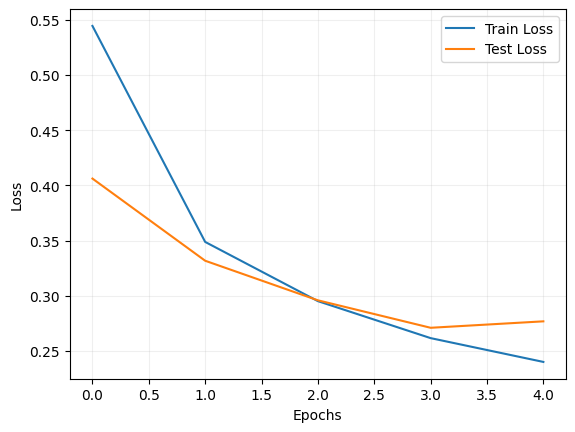

In [ ]:
plt.plot(cnn_train_history.history['loss'], label='Train Loss')
plt.plot(cnn_train_history.history['val_loss'], label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(alpha=0.2)
plt.legend()
plt.show()

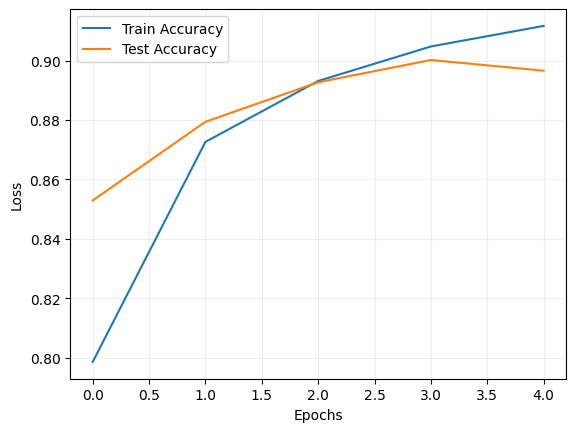

In [ ]:
plt.plot(cnn_train_history.history['accuracy'], label='Train Accuracy')
plt.plot(cnn_train_history.history['val_accuracy'], label='Test Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(alpha=0.2)
plt.legend()
plt.show()

In [ ]:
cnn_Y_pred = cnn_model.predict(X_test_normalized)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


In [ ]:
cnn_y_pred = np.argmax(cnn_Y_pred, axis=-1)

In [ ]:
cnn_test_accuracy = np.mean(cnn_y_pred == y_test)
print(cnn_test_accuracy)

0.8969


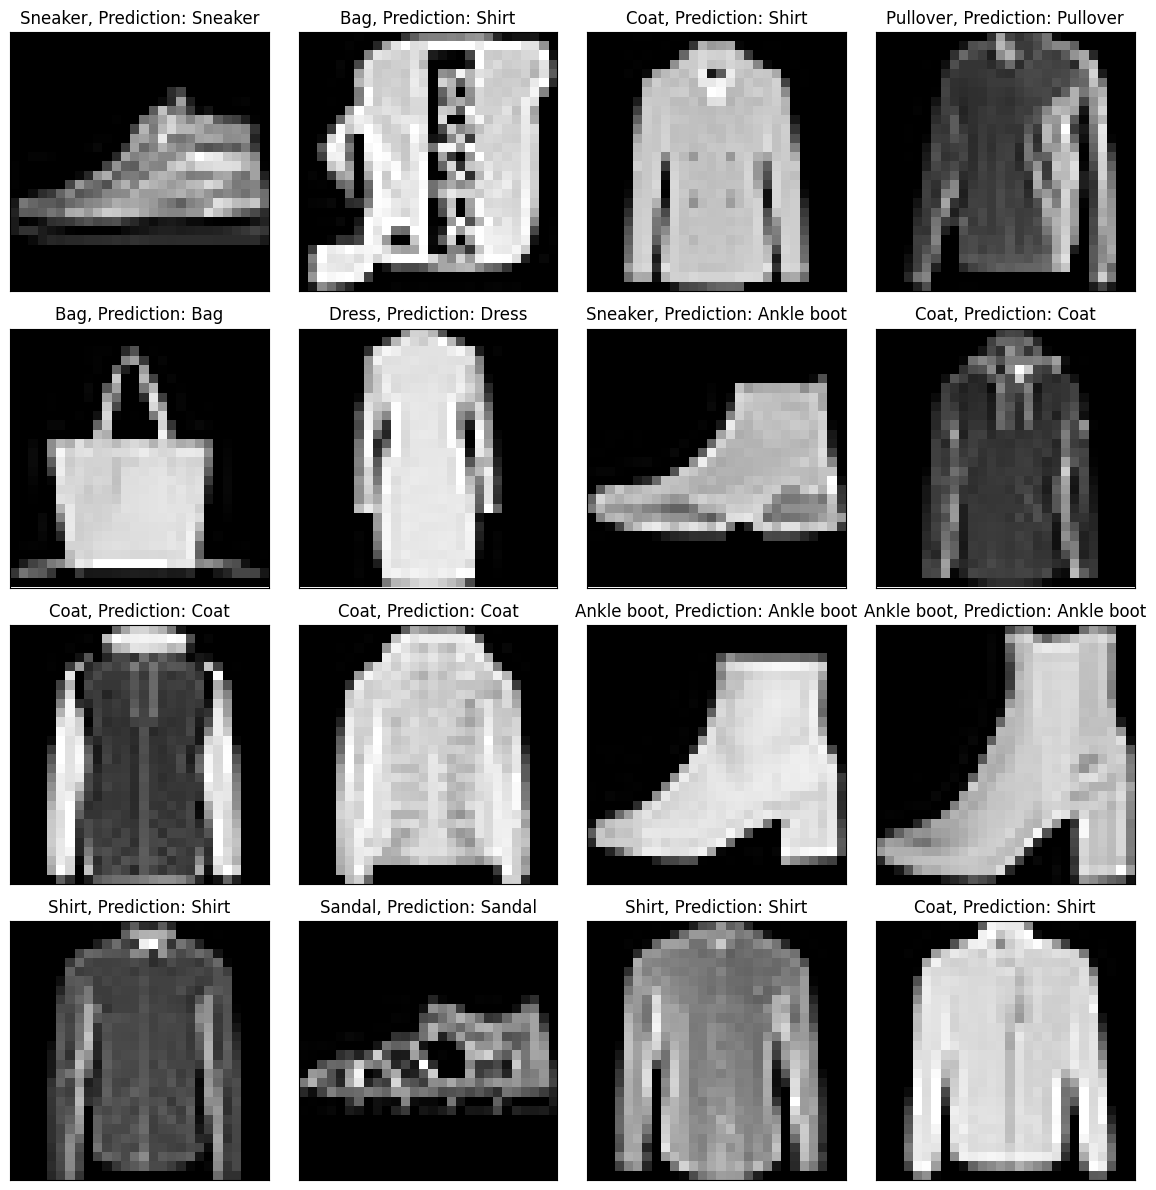

In [ ]:
plt.figure(figsize=(12, 12))
n = 4
for i in range(n * n):
    plt.subplot(n, n, i+1)
    random_idx = np.random.randint(0, X_test.shape[0])
    plt.imshow(X_test[random_idx], cmap='gray')
    plt.title(f'{label_dict[y_test[random_idx]]}, Prediction: {label_dict[cnn_y_pred[random_idx]]}')
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()